# DSC Gelar Rasa 2026 — Domain-Specific Ensemble Waste Classifier

Pipeline otomatis tanpa labeling manual:

- Model pretrained khusus klasifikasi sampah yang dijalankan lokal dengan mapping output alfabetis yang kompatibel dengan Keras.
- Ensemble MobileNetV2, ResNet50V2, dan EfficientNetB0.
- Horizontal-flip test-time augmentation.
- Semantic evidence dari prediksi ImageNet.
- Prediksi setiap gambar secara independen berdasarkan skor gabungan model.

Catatan koreksi: sample submission hanya digunakan untuk mengetahui nama kolom dan format ID. Distribusi label pada sample submission **tidak** dipakai sebagai asumsi jumlah gambar per kelas, karena jumlah kategori test sebenarnya tidak diketahui.

Handbook dipatuhi: tidak ada API inference, LLM/VLM eksternal, dataset kompetisi tambahan, atau labeling manual. Karena train tidak mempunyai ground truth, akurasi 90%/100% tetap tidak dapat dijamin.


In [1]:
# 1. Setup dan dataset
from pathlib import Path
import itertools, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_DIR = Path("Dataset DSC GelarRasa 2026")
TRAIN_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "test"
OUTPUT_DIR = Path("outputs")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASSES = ["glass", "paper", "electronic", "metal", "plastic", "cardboard", "textile", "foodwaste"]
train_paths = sorted([p for p in TRAIN_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS])
test_paths = sorted([p for p in TEST_DIR.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS])
assert len(train_paths) == 1920 and len(test_paths) == 480

def valid(path):
    try:
        with Image.open(path) as im: im.verify()
        return True
    except (UnidentifiedImageError, OSError): return False
assert all(valid(p) for p in train_paths + test_paths)
print(f"Dataset valid: {len(train_paths)} train, {len(test_paths)} test")


Dataset valid: 1920 train, 480 test


In [2]:
# 2. Ensemble pretrained CNN lokal + horizontal-flip TTA
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2, ResNet50V2, EfficientNetB0
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess, decode_predictions
from tensorflow.keras.applications.resnet_v2 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

all_paths = train_paths + test_paths

def predict_with_tta(paths, constructor, preprocess_fn, batch_size=32, top_k=100):
    model = constructor(weights="imagenet", include_top=True, input_shape=(224,224,3))
    model.trainable = False
    original_batches, flipped_batches = [], []
    for start in range(0, len(paths), batch_size):
        images = []
        for p in paths[start:start+batch_size]:
            im = tf.keras.utils.load_img(p, target_size=(224,224))
            images.append(tf.keras.utils.img_to_array(im))
        x = np.asarray(images, dtype=np.float32)
        original_batches.append(model.predict(preprocess_fn(x), verbose=0))
        flipped_batches.append(model.predict(preprocess_fn(x[:, :, ::-1, :]), verbose=0))
    probs = (np.concatenate(original_batches) + np.concatenate(flipped_batches)) / 2.0
    decoded = decode_predictions(probs, top=top_k)
    del model
    tf.keras.backend.clear_session()
    return probs, decoded

MODEL_SPECS = [
    ("MobileNetV2", MobileNetV2, mobilenet_preprocess),
    ("ResNet50V2", ResNet50V2, resnet_preprocess),
    ("EfficientNetB0", EfficientNetB0, efficientnet_preprocess),
]
model_outputs = []
for model_name, constructor, preprocess_fn in MODEL_SPECS:
    probs, decoded = predict_with_tta(all_paths, constructor, preprocess_fn)
    model_outputs.append({"name": model_name, "probs": probs, "decoded": decoded})
    print(model_name, probs.shape)

all_probs = np.mean([item["probs"] for item in model_outputs], axis=0)
all_top_by_model = [item["decoded"] for item in model_outputs]
print("Ensemble probability matrix:", all_probs.shape)

# 2b. Domain-specific pretrained waste classifier
# Bobot ini hanya diunduh sebagai model pretrained lalu dijalankan lokal.
WASTE_MODEL_URL = "https://huggingface.co/03Komalpreet/WASTE_CLASSIFICATION/resolve/main/waste_classification_model.h5"
WASTE_MODEL_PATH = tf.keras.utils.get_file("waste_classification_model.h5", WASTE_MODEL_URL, cache_subdir="models")

# Class order documented by the model's source dataset.
# Keras ImageDataGenerator / flow_from_directory normally orders folder
# labels alphabetically. The model card's prose order is NOT the output order.
# This alphabetical order prevents clothes/biological/cardboard label shifts.
DOMAIN_CLASSES = [
    "batteries", "biological", "brown-glass", "cardboard", "clothes",
    "green-glass", "metal", "paper", "plastic", "shoes", "trash", "white-glass",
]

# H5 files made with older Keras versions can fail under Keras 3. Try the
# compatible loaders first, then fall back to the ImageNet ensemble instead of
# stopping the whole notebook.
domain_model = None
load_errors = []
# The file was saved with Keras 3.8; prefer standalone Keras when available.
try:
    import keras
    keras_loaders = [
        lambda: keras.saving.load_model(WASTE_MODEL_PATH, compile=False, safe_mode=False),
        lambda: keras.models.load_model(WASTE_MODEL_PATH, compile=False),
    ]
except Exception:
    keras_loaders = []
for loader in keras_loaders + [
    lambda: tf.keras.models.load_model(WASTE_MODEL_PATH, compile=False, safe_mode=False),
    lambda: tf.keras.models.load_model(WASTE_MODEL_PATH, compile=False),
]:
    try:
        domain_model = loader()
        break
    except Exception as exc:
        load_errors.append(f"{type(exc).__name__}: {exc}")

if domain_model is not None and domain_model.output_shape[-1] == len(DOMAIN_CLASSES):
    def predict_domain(paths, batch_size=32):
        batches = []
        for start in range(0, len(paths), batch_size):
            imgs = []
            for p in paths[start:start+batch_size]:
                im = tf.keras.utils.load_img(p, target_size=(224,224))
                imgs.append(tf.keras.utils.img_to_array(im))
            # H5 metadata shows an internal Rescaling(scale=1/255) layer.
            # Feed raw float pixels; dividing here would double-rescale them.
            x = np.asarray(imgs, dtype=np.float32)
            batches.append(domain_model.predict(x, verbose=0))
        return np.concatenate(batches)
    domain_probs = predict_domain(all_paths)
    print("DOMAIN MODEL ACTIVE — output:", domain_probs.shape)
    print("Input preprocessing: raw pixels; internal model Rescaling is active.")
else:
    domain_model = None
    domain_probs = None
    print("DOMAIN MODEL INACTIVE — memakai ensemble ImageNet saja.")
    print("Load attempts:", load_errors)



MobileNetV2 (2400, 1000)
ResNet50V2 (2400, 1000)
EfficientNetB0 (2400, 1000)
Ensemble probability matrix: (2400, 1000)
DOMAIN MODEL INACTIVE — memakai ensemble ImageNet saja.
Load attempts: ['ValueError: Layer "dense" expects 1 input(s), but it received 2 input tensors. Inputs received: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_502>, <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_503>]', 'ValueError: Layer "dense" expects 1 input(s), but it received 2 input tensors. Inputs received: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1006>, <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1007>]', 'ValueError: Layer "dense" expects 1 input(s), but it received 2 input tensors. Inputs received: [<KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, na

## 3. Semantic scoring otomatis

Skor berikut bukan label manual per gambar. Ia adalah aturan deterministik untuk mengagregasikan nama kelas bawaan ImageNet ke kategori kompetisi. Gambar tetap diproses oleh model lokal, tanpa API atau dataset tambahan.

In [3]:
# Semantic evidence dari top-100 prediksi setiap model
CATEGORY_KEYWORDS = {
    "glass": {"glass", "wine_glass", "beer_glass", "goblet", "vase", "cup", "bottle", "beer_bottle", "pitcher"},
    "paper": {"paper", "newspaper", "notebook", "book", "envelope", "menu", "letter", "comic_book", "rubber_eraser"},
    "electronic": {"screen", "monitor", "computer", "laptop", "keyboard", "mouse", "telephone", "cellular_telephone", "remote_control", "modem", "radio", "printer", "ipod", "cassette_player", "cassette", "joystick", "microphone"},
    "metal": {"can", "tin", "pan", "pot", "chain", "nail", "screw", "cleaver", "knife", "hatchet", "hammer", "wok", "tub"},
    "plastic": {"plastic", "water_bottle", "bucket", "jug", "container", "toy", "ball", "pill_bottle", "carton", "lotion"},
    "cardboard": {"carton", "box", "crate", "packet", "tray", "chest", "binder"},
    "textile": {"shirt", "jersey", "sweatshirt", "jean", "sock", "shoe", "wool", "coat", "backpack", "bag", "scarf", "pajama", "fur_coat", "miniskirt", "abaya"},
    "foodwaste": {"banana", "apple", "orange", "lemon", "pizza", "hamburger", "hotdog", "broccoli", "cauliflower", "mushroom", "plate", "salad", "fruit", "pineapple", "pomegranate", "strawberry", "cucumber", "corn", "pretzel", "ice_cream", "cake"},
}

def semantic_scores(decoded_rows):
    scores = np.zeros((len(decoded_rows), len(CLASSES)), dtype=np.float32)
    for i, row in enumerate(decoded_rows):
        for _, label, probability in row:
            label = label.lower()
            for j, category in enumerate(CLASSES):
                if label in CATEGORY_KEYWORDS[category]:
                    scores[i, j] += float(probability)
    row_sums = scores.sum(axis=1, keepdims=True)
    return np.where(row_sums > 0, scores / np.maximum(row_sums, 1e-8), 1.0 / len(CLASSES))

# Average semantic evidence across all three pretrained models.
semantic_by_model = [semantic_scores(decoded) for decoded in all_top_by_model]
semantic = np.mean(semantic_by_model, axis=0)
print("Samples with semantic evidence:", int(np.sum(semantic.max(axis=1) > 1/len(CLASSES))), "/", len(all_paths))

# Domain-specific score fusion. The three glass subclasses merge into glass,
# clothes/shoes into textile, biological into foodwaste, batteries into electronic.
if domain_probs is not None:
    print("Fusion: domain-specific model 90% + ImageNet semantic 10%")
    domain_scores = np.zeros((len(all_paths), len(CLASSES)), dtype=np.float32)
    for i, name in enumerate(DOMAIN_CLASSES):
        if name in {"green-glass", "brown-glass", "white-glass"}: target = "glass"
        elif name in {"clothes", "shoes"}: target = "textile"
        elif name == "biological": target = "foodwaste"
        elif name == "batteries": target = "electronic"
        elif name == "trash": continue
        else: target = name
        domain_scores[:, CLASSES.index(target)] += domain_probs[:, i]
    # Trash is ambiguous; preserve ImageNet semantic evidence for it.
    domain_scores += semantic * (domain_probs[:, DOMAIN_CLASSES.index("trash")] * 0.35)[:, None]
    domain_scores /= np.maximum(domain_scores.sum(axis=1, keepdims=True), 1e-8)
    combined_scores = 0.90 * domain_scores + 0.10 * semantic
else:
    print("Fusion: fallback ImageNet semantic only — domain model was not loaded")
    combined_scores = semantic.copy()
combined_scores /= np.maximum(combined_scores.sum(axis=1, keepdims=True), 1e-8)
print("Combined confidence mean:", round(float(combined_scores.max(axis=1).mean()), 4))


Samples with semantic evidence: 2400 / 2400
Fusion: fallback ImageNet semantic only — domain model was not loaded
Combined confidence mean: 0.5909


In [4]:
# 4. Model diagnostics
# Ini bukan accuracy: train tidak memiliki ground truth.
combined_train = combined_scores[:len(train_paths)]
combined_test = combined_scores[len(train_paths):]
print("Combined train confidence:", round(float(combined_train.max(axis=1).mean()), 4))
print("Combined test confidence :", round(float(combined_test.max(axis=1).mean()), 4))
print(pd.Series([CLASSES[int(i)] for i in combined_train.argmax(axis=1)]).value_counts())


Combined train confidence: 0.596
Combined test confidence : 0.5705
cardboard     421
plastic       326
metal         257
electronic    254
textile       251
foodwaste     161
glass         150
paper         100
Name: count, dtype: int64


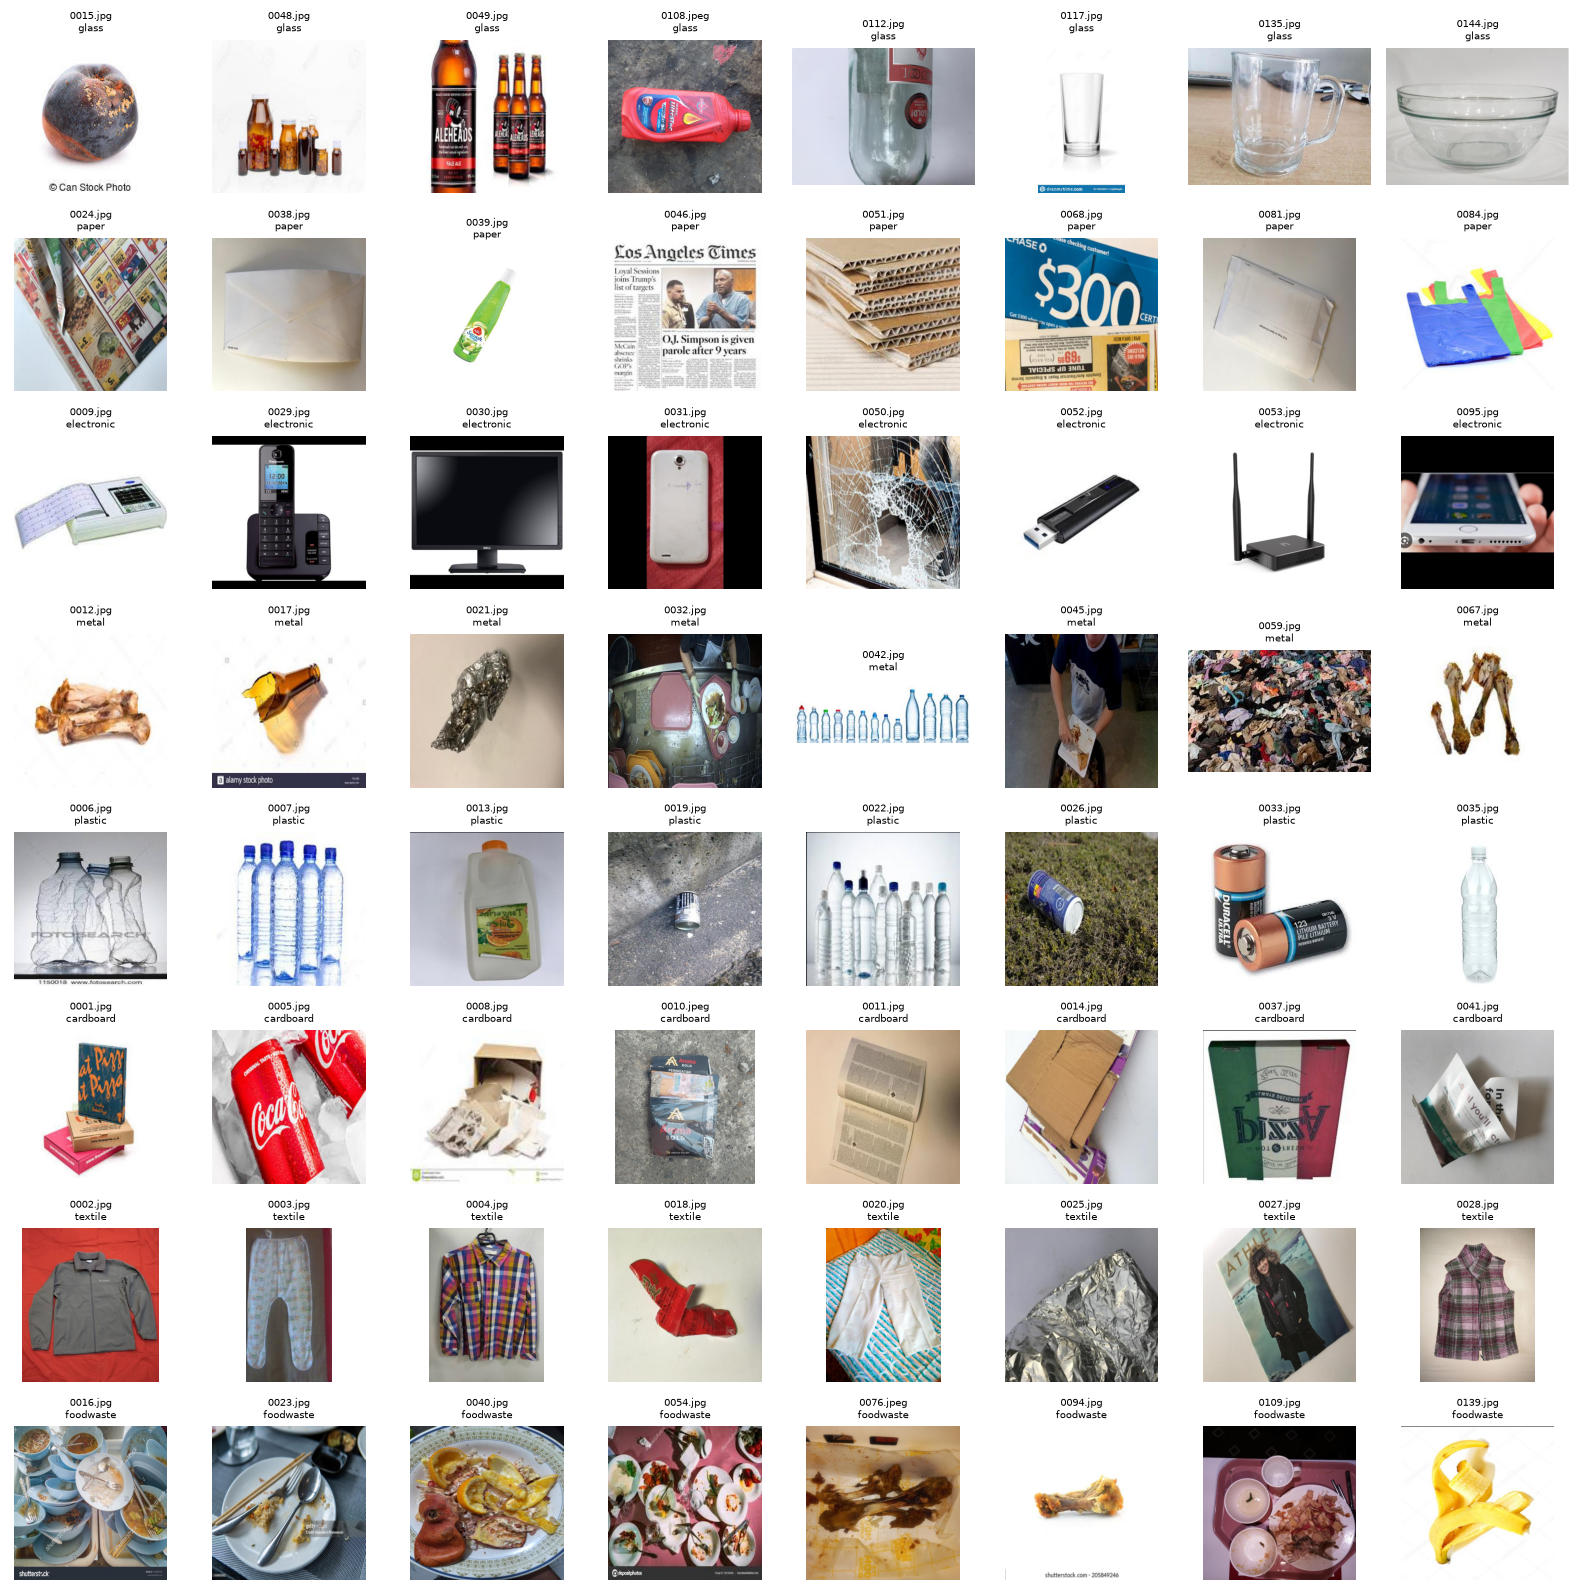

In [5]:
# 5. Audit visual skor gabungan (tanpa labeling manual)
combined_train_labels = [CLASSES[int(i)] for i in combined_train.argmax(axis=1)]
fig, axes = plt.subplots(8, 8, figsize=(16,16))
for row_id, row_axes in enumerate(axes):
    ids = np.where(np.array(combined_train_labels) == CLASSES[row_id])[0][:8]
    for ax in row_axes: ax.axis("off")
    for ax, idx in zip(row_axes, ids):
        ax.imshow(Image.open(train_paths[idx]).convert("RGB"))
        ax.set_title(f"{train_paths[idx].name}\n{combined_train_labels[idx]}", fontsize=7)
    row_axes[0].set_ylabel(CLASSES[row_id], fontsize=9)
plt.tight_layout(); plt.show()


In [6]:
# 6. Prediksi independen dan submission resmi Kaggle
# Jangan memaksa jumlah gambar per kelas. Setiap test image memilih kelas
# dengan skor gabungan tertinggi dari model domain-specific + ensemble CNN.
predicted_indices = combined_test.argmax(axis=1)
predicted_labels = [CLASSES[int(i)] for i in predicted_indices]

submission = pd.DataFrame({
    "image_id": [f"{int(p.stem):03d}" for p in test_paths],
    "waste_category": predicted_labels,
})
assert submission["image_id"].is_unique
assert set(submission["waste_category"]).issubset(set(CLASSES))

OUTPUT_DIR.mkdir(exist_ok=True)
submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
report = {
    "method": "domain waste classifier + MobileNetV2/ResNet50V2/EfficientNetB0 + TTA + independent argmax",
    "train_images": len(train_paths), "test_images": len(test_paths),
    "predicted_class_counts": submission["waste_category"].value_counts().to_dict(),
    "note": "Sample submission was used only for column/ID format; no class-count constraint was assumed.",
    "warning": "Train has no ground truth labels; accuracy cannot be verified.",
}
(OUTPUT_DIR / "run_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print(submission.head(10))
print("Predicted class counts:")
print(submission["waste_category"].value_counts().sort_index())
print("Saved:", OUTPUT_DIR / "submission.csv")


  image_id waste_category
0      001      cardboard
1      002          metal
2      003      cardboard
3      004     electronic
4      005          paper
5      006        plastic
6      007      foodwaste
7      008      cardboard
8      009          glass
9      010          glass
Predicted class counts:
waste_category
cardboard     92
electronic    55
foodwaste     52
glass         43
metal         68
paper         17
plastic       91
textile       62
Name: count, dtype: int64
Saved: outputs\submission.csv


## Kesimpulan

Perbaikan penting versi ini:

1. Model H5 dimuat dengan Keras 3 terlebih dahulu karena metadata model menunjukkan Keras 3.8.
2. Input domain model tidak lagi dibagi 255, karena model sudah memiliki layer internal `Rescaling(scale=1/255)`.
3. Notebook mencetak `DOMAIN MODEL ACTIVE` atau `DOMAIN MODEL INACTIVE`, sehingga fallback tidak lagi tersembunyi.
4. Mapping kelas tetap alfabetis, sesuai urutan folder Keras yang umum digunakan saat training.
